# Exploratory Data Analysis (EDA)

This notebook looks at the purchase data before any modelling. We check what each column
holds, where the data has errors or gaps, and which columns relate to the target
`repeat_purchase_90d` (1 means the customer buys again within 90 days).

We don't change the data here. We write down what we find, and the preprocessing
notebook decides what to do about it and tests each decision.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
from scipy.stats import chi2_contingency, pointbiserialr

PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
FIGSIZE = (10, 6)

## 1. First look at the data

We read `train.csv` with `ID` as the index, so the model never sees it as a feature.
Then we check the size of the table, how each column is stored, and how many values
each one has filled in.

In [2]:
# ID as index so it never ends up as a feature
raw = pd.read_csv("../data/train.csv", index_col="ID")

print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns, indexed by ID")
raw.head()

6,534 rows x 38 columns, indexed by ID


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [3]:
raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

## 2. The role of each column

A common rule treats a column with many distinct values as an
identifier. Here it fails both ways: it flags money columns, which are measurements,
and it misses `customer_id`, the real identifier. So we set the identifier by hand and
split the other columns into numeric and categorical.

In [4]:
# columns where more than half the values are distinct
many_distinct = {c: raw[c].nunique() for c in raw.columns
                 if raw[c].nunique() > 0.5 * len(raw)}
many_distinct

{'Total a Pagar': 6122,
 'Total Bruto': 6038,
 'Total Liquido': 6093,
 'Total Imp_': 5407,
 'Total Desc_ Linha': 3520,
 'Custo': 5740,
 'prior_total_spend': 5864,
 'prior_mean_purchase_value': 5652,
 'prior_std_purchase_value': 5420,
 'prior_mean_gap_days': 3874,
 'prior_std_gap_days': 4911,
 'spend_90d': 3523,
 'spend_180d': 5021,
 'spend_365d': 5434,
 'random_noise': 6469}

In [5]:
# the rule above doesn't work here, so customer_id is set by hand
identifiers = ["customer_id"]
target = "repeat_purchase_90d"
dates = ["purchase_date"]
numeric = [c for c in raw.columns
           if c not in identifiers + [target]
           and pd.api.types.is_numeric_dtype(raw[c])]
categorical = [c for c in raw.columns
               if c not in identifiers + [target] + dates + numeric]

# numeric columns with few distinct values may be labels
low_cardinality = {c: raw[c].nunique() for c in numeric if raw[c].nunique() <= 10}
levels = raw[categorical].nunique().sort_values(ascending=False)

# list the levels of small categoricals to spot typos
for column in levels[levels <= 10].index:
    print(f"{column:18s} {sorted(raw[column].dropna().unique())}")

roles = pd.Series({
    "identifiers": f"{len(identifiers)} {identifiers}",
    "dates": f"{len(dates)} {dates}",
    "numeric": f"{len(numeric)}, of which low-cardinality: {low_cardinality}",
    "categorical": f"{len(categorical)}, holding {int(levels.sum())} levels",
    "target": target,
    "'customer_id' passes select_dtypes('number')":
        "customer_id" in raw.select_dtypes("number").columns,
})
print()
print(roles.to_frame("what each group holds").to_string())
levels.to_frame("levels")

payment_type       ['Maybe Tomorrow Payment 10', 'Maybe Tomorrow Payment 11', 'Maybe Tomorrow Payment 12', 'Maybe Tomorrow Payment 2', 'Maybe Tomorrow Payment 3', 'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 7', 'Maybe Tomorrow Payment 8', 'Maybe Tomorrow Payment 9']
salesperson        ['VLOOKUP Master 1', 'VLOOKUP Master 2', 'VLOOKUP Master 3', 'VLOOKUP Master 4', 'VLOOKUP Master 5', 'VLOOKUP Master 6', 'VLOOKUP Master 7', 'VLOOKUP Master 8', 'VLOOKUP Master 9']
commercial_zone    ['Decorative Dashboard Zone 2', 'Decorative Dashboard Zone 3', 'Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
document_series    ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']
warehouse          ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']

                                                                                            what each group holds
identifiers                                                                         

,levels
transport_method,80
payment_type,9
salesperson,9
commercial_zone,5
document_series,3
warehouse,2


## 3. Repeated rows and repeated customers

The duplicate check finds 10 rows, but they are almost empty rows with only the
customer and the target, so nothing is removed. What repeats is the customer:
610 customers make 6,534 purchases. When we evaluate models later, a customer's
past and future purchases must not be mixed between training and validation.

In [6]:
duplicate_rows = raw.duplicated().sum()
print("duplicates ignoring the index:", duplicate_rows)

per_customer = raw.groupby("customer_id").size()
print(f"\ndistinct customers: {len(per_customer)}")
print(f"rows sharing a 'customer_id': {per_customer[per_customer > 1].sum()}"
      f" across {(per_customer > 1).sum()} customers")
print(f"customers with a single row: {(per_customer == 1).sum()}")
per_customer.describe().round(2).to_frame("rows per customer").T

duplicates ignoring the index: 10

distinct customers: 610
rows sharing a 'customer_id': 6377 across 453 customers
customers with a single row: 157


,count,mean,std,min,25%,50%,75%,max
rows per customer,610.0,10.71,19.97,1.0,1.0,4.0,12.0,277.0


In [7]:
# keep=False marks every copy, not just the repeats
duplicated_rows = raw[raw.duplicated(keep=False)]
print("rows involved:", len(duplicated_rows))
print("missing values per row, in those rows:",
      duplicated_rows.isna().sum(axis=1).value_counts().to_dict())

rows involved: 16
missing values per row, in those rows: {36: 16}


## 4. The target

56% of purchases are followed by another purchase within 90 days, so the two classes
are close to balanced. Always predicting 1 would already be right 56% of the time,
which is the baseline any model has to beat.

In [8]:
balance = raw[target].value_counts().sort_index()
print(balance.to_frame("rows").assign(
    share=lambda f: (f["rows"] / len(raw)).round(4)).to_string())

print(f"\nalways predicting the majority class scores"
      f" {balance.max() / balance.sum():.4f} accuracy and 0 recall on the other")

                     rows   share
repeat_purchase_90d              
0                    2880  0.4408
1                    3654  0.5592

always predicting the majority class scores 0.5592 accuracy and 0 recall on the other


## 5. Missing values

40% of the rows have at least one missing value, so deleting incomplete rows would throw
away too much data. The gaps fall into three groups: 65 almost empty rows, the customer
history columns, and five columns that each miss about 3% of their values.

In [9]:
rows_with_null = raw.isna().any(axis=1)
per_column = raw.isna().sum()

pd.Series({
    "rows with a null": f"{rows_with_null.sum():,} of {len(raw):,}"
                        f" ({100 * rows_with_null.mean():.2f}%)",
    "columns with a null": f"{(per_column > 0).sum()} of {raw.shape[1]}",
    "null cells": f"{raw.isna().sum().sum():,}",
    "worst column": f"{per_column.idxmax()} ({per_column.max()} nulls)",
}).to_frame("missing values as the file arrives")

,missing values as the file arrives
rows with a null,"2,605 of 6,534 (39.87%)"
columns with a null,36 of 38
null cells,"9,818"
worst column,prior_std_gap_days (1478 nulls)


In [10]:
# missing values per row
per_row = raw.isna().sum(axis=1)
per_row.value_counts().sort_index().to_frame("rows").T

,0,1,2,3,4,5,7,8,9,36
rows,3929,1287,190,354,100,6,511,86,6,65


In [11]:
# rows with 36 missing values, then the missing values left without them
empty_rows = per_row == 36
print("empty rows:", empty_rows.sum(),
      "| distinct customers in them:", raw.loc[empty_rows, "customer_id"].nunique())
print("filled columns in those rows:",
      raw[empty_rows].notna().sum()[lambda s: s > 0].to_dict())

per_column_rest = raw[~empty_rows].isna().sum()
per_column_rest[per_column_rest > 0].sort_values(ascending=False).to_frame("nulls")

empty rows: 65 | distinct customers in them: 53
filled columns in those rows: {'repeat_purchase_90d': 65, 'customer_id': 65}


,nulls
prior_std_gap_days,1413
prior_mean_gap_days,1243
prior_std_purchase_value,1048
prior_mean_purchase_value,797
days_since_previous_purchase,796
prior_min_purchase_value,603
prior_max_purchase_value,603
transport_method,196
spend_365d,195
payment_type,195


## 6. How the numeric columns look

We look at summary statistics, skewness and a histogram of one money column.
27 of the 29 numeric columns have a long right tail: a few very large purchases pull
the mean up. In `Total a Pagar`, the median purchase is about €477 while the mean is
€926, so from here on we use the median to describe a typical value.

In [12]:
summary = raw[numeric].describe().T
print(summary.round(2).to_string())

                                 count        mean          std        min      25%      50%       75%           max
Total a Pagar                   6469.0      925.56      1335.00       0.93   188.92   476.74   1087.67  2.229721e+04
Total Bruto                     6469.0      886.15      1327.64       0.83   175.74   445.74   1036.70  2.157828e+04
Total Liquido                   6469.0      773.34      1136.36       0.76   154.38   389.91    903.37  1.812781e+04
Total Imp_                      6469.0      152.22       225.26       0.00    29.93    79.74    184.84  4.169400e+03
Total Portes                    6469.0        1.15         5.84       0.00     0.00     0.00      0.00  1.810600e+02
Total Desc_ Global              6469.0        0.35         5.12       0.00     0.00     0.00      0.00  2.184900e+02
Total Desc_ Linha               6469.0      112.47       289.99       0.00     0.00    13.13     92.28  4.103440e+03
Custo                           6469.0      328.17       519.51 

In [13]:
# skewness, mean vs median and % of zeros
shape = summary.copy()
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)  # avoid dividing by 0
shape["skew"] = raw[numeric].skew()
shape["% zeros"] = 100 * (raw[numeric] == 0).mean()
shape = shape.sort_values("skew", ascending=False)

print(shape[["mean", "50%", "mean/median", "skew", "% zeros"]].round(2).to_string())
print("\ncolumns with |skew| > 1:", (shape["skew"].abs() > 1).sum(), "of", len(shape))

                                      mean      50%  mean/median   skew  % zeros
Total Desc_ Global                    0.35     0.00          NaN  27.46    97.32
prior_max_purchase_value           2946.38  1783.24         1.65  21.34     0.00
spend_365d                      2396534.88  2426.60       987.61  20.38    12.40
Total Portes                          1.15     0.00          NaN  19.55    82.89
prior_mean_purchase_value       2821825.32   724.90      3892.73  18.75     0.00
prior_mean_gap_days                  95.88    68.44         1.40   9.30     0.00
prior_std_gap_days                   74.14    50.64         1.46   7.77     0.02
days_since_previous_purchase        101.53    57.00         1.78   6.53     0.00
invoice_count_current_purchase        1.07     1.00         1.07   6.44     0.00
Total Desc_ Linha                   112.47    13.13         8.57   5.92    37.36
prior_min_purchase_value            185.46    64.34         2.88   5.90     0.00
spend_30d                   

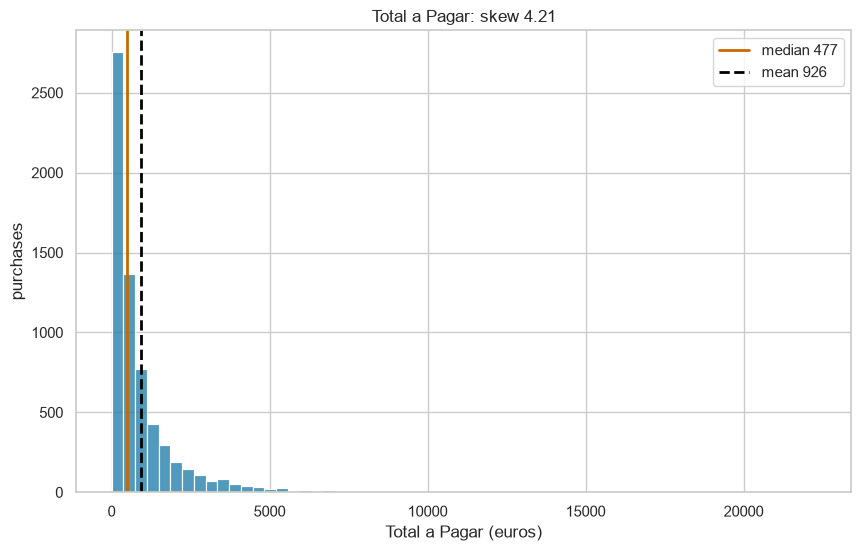

In [14]:
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.histplot(raw["Total a Pagar"].dropna(), bins=60, color=PLOT_BLUE, ax=ax)
ax.axvline(raw["Total a Pagar"].median(), color=PLOT_ORANGE, lw=2,
           label=f"median {raw['Total a Pagar'].median():.0f}")
ax.axvline(raw["Total a Pagar"].mean(), color="black", lw=2, ls="--",
           label=f"mean {raw['Total a Pagar'].mean():.0f}")
ax.set(xlabel="Total a Pagar (euros)", ylabel="purchases",
       title=f"Total a Pagar: skew {raw['Total a Pagar'].skew():.2f}")
ax.legend()
plt.show()

## 7. Impossible values

Some values cannot be true: −4 days, €1,000,000,000, negative spending, and averages
larger than the maximum. Domain rules and checks between columns find 139 such cells.
We set them to missing in a copy of the data and keep the original table unchanged,
because a missing value says "we don't know" while a wrong value misleads every statistic.

In [15]:
non_negative = [c for c in numeric if c != "random_noise"]
negative_rows = (raw[non_negative] < 0).sum()
for column in negative_rows[negative_rows > 0].index:
    print(f"{column:30s} min {raw[column].min():12.1f}   negative rows"
          f" {negative_rows[column]:4d}")

for column in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    print(f"\n{column}:",
          raw.loc[raw[column] < 0, column].value_counts().to_dict())

placeholder_rows = (raw[numeric] == 1e9).sum()
print("\nrows at exactly 1e9:",
      placeholder_rows[placeholder_rows > 0].to_dict())
for column in placeholder_rows[placeholder_rows > 0].index:
    print(f"largest {column} without those rows:"
          f" {raw.loc[raw[column] < 1e9, column].max():,.2f}")

days_since_previous_purchase   min         -4.0   negative rows   16
prior_mean_purchase_value      min      -2478.7   negative rows   16
prior_mean_gap_days            min         -4.0   negative rows   16
spend_365d                     min    -159115.2   negative rows   15

days_since_previous_purchase: {-4.0: 16}

prior_mean_gap_days: {-4.0: 16}

rows at exactly 1e9: {'prior_mean_purchase_value': 16, 'spend_365d': 15}
largest prior_mean_purchase_value without those rows: 72,937.16
largest spend_365d without those rows: 522,933.21


In [16]:
# columns that should add up (empty rows left out, 2 cent tolerance)
complete = raw[~empty_rows]

checks = pd.Series({
    "Total a Pagar != Total Liquido + Total Imp_":
        ((complete["Total a Pagar"] - complete["Total Liquido"]
          - complete["Total Imp_"]).abs() > 0.02).sum(),
    "Total Liquido != Total Bruto - Desc_ Linha - Desc_ Global":
        ((complete["Total Liquido"] - complete["Total Bruto"]
          + complete["Total Desc_ Linha"] + complete["Total Desc_ Global"]).abs() > 0.02).sum(),
    "window counts that do not grow (30d <= 90d <= 180d <= 365d)":
        ((complete["purchase_count_30d"] > complete["purchase_count_90d"])
         | (complete["purchase_count_90d"] > complete["purchase_count_180d"])
         | (complete["purchase_count_180d"] > complete["purchase_count_365d"])).sum(),
    "purchase_count_365d > prior_purchase_count":
        (complete["purchase_count_365d"] > complete["prior_purchase_count"]).sum(),
    "spend_365d < spend_180d":
        (complete["spend_365d"] < complete["spend_180d"] - 0.02).sum(),
    "prior_min_purchase_value > prior_max_purchase_value":
        (complete["prior_min_purchase_value"] > complete["prior_max_purchase_value"]).sum(),
    "prior_mean_purchase_value outside [prior_min, prior_max]":
        ((complete["prior_mean_purchase_value"] < complete["prior_min_purchase_value"] - 0.02)
         | (complete["prior_mean_purchase_value"] > complete["prior_max_purchase_value"] + 0.02)).sum(),
    "prior_mean_purchase_value != prior_total_spend / prior_purchase_count":
        ((complete["prior_mean_purchase_value"] - complete["prior_total_spend"]
          / complete["prior_purchase_count"]).abs() > 0.02).sum(),
    "Custo > Total Liquido":
        (complete["Custo"] > complete["Total Liquido"]).sum(),
})
print(checks.to_frame("rows that fail").to_string())

                                                                       rows that fail
Total a Pagar != Total Liquido + Total Imp_                                         0
Total Liquido != Total Bruto - Desc_ Linha - Desc_ Global                           0
window counts that do not grow (30d <= 90d <= 180d <= 365d)                         0
purchase_count_365d > prior_purchase_count                                          0
spend_365d < spend_180d                                                            15
prior_min_purchase_value > prior_max_purchase_value                                 0
prior_mean_purchase_value outside [prior_min, prior_max]                           77
prior_mean_purchase_value != prior_total_spend / prior_purchase_count              78
Custo > Total Liquido                                                              39


In [17]:
# work on a copy so raw stays as it was loaded
invalid_errors = {
    "days_since_previous_purchase": lambda values: values < 0,
    "prior_mean_gap_days": lambda values: values < 0,
    "prior_mean_purchase_value": lambda values: (values < 0) | (values == 1e9),
    "spend_365d": lambda values: (values < 0) | (values == 1e9),
}

checked = raw.copy()
for column, is_invalid in invalid_errors.items():
    checked[column] = checked[column].mask(is_invalid(checked[column]))

# two-column rule: a mean cannot be larger than the maximum
above_max = (checked["prior_mean_purchase_value"]
             > checked["prior_max_purchase_value"] + 0.02)
checked["prior_mean_purchase_value"] = checked["prior_mean_purchase_value"].mask(above_max)

print(f"means above the maximum, after the one-column rules: {above_max.sum()}")
print(f"null cells: {raw.isna().sum().sum():,} -> {checked.isna().sum().sum():,}")
print("spend_365d < spend_180d, after:",
      (checked["spend_365d"] < checked["spend_180d"] - 0.02).sum())
print("prior_mean != prior_total_spend / prior_purchase_count, after:",
      ((checked["prior_mean_purchase_value"] - checked["prior_total_spend"]
        / checked["prior_purchase_count"]).abs() > 0.02).sum(), "\n")
print(checked[list(invalid_errors)].describe().T.round(2).to_string())

means above the maximum, after the one-column rules: 45
null cells: 9,818 -> 9,957
spend_365d < spend_180d, after: 0
prior_mean != prior_total_spend / prior_purchase_count, after: 1 

                               count     mean       std   min     25%      50%      75%        max
days_since_previous_purchase  5657.0   101.83    165.84  1.00   17.00    57.00   119.00    3199.00
prior_mean_gap_days           5210.0    96.18    122.65  1.00   42.86    68.61   114.00    3199.00
prior_mean_purchase_value     5595.0   870.21    745.62  3.31  357.84   718.97  1078.22    6685.17
spend_365d                    6244.0  5777.74  13900.88  0.00  643.29  2426.60  7010.41  522933.21


## 8. Why values are missing

The history columns are empty when the value cannot exist yet: a first purchase has no
previous purchase to describe, and a second one has no spread between purchases yet.
First purchases also behave differently. Only 33% of them are followed by another
purchase within 90 days, compared with 58% of the other purchases.

In [18]:
# share of missing history values by number of previous purchases
history = ["days_since_previous_purchase", "prior_mean_purchase_value",
           "prior_min_purchase_value", "prior_max_purchase_value",
           "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

print("rows by number of previous purchases:",
      complete["prior_purchase_count"].value_counts().sort_index().head(5).to_dict())
by_prior_count = complete[history].isna().groupby(complete["prior_purchase_count"]).mean()
print(by_prior_count.head(5).round(3).T.to_string())

rows by number of previous purchases: {0.0: 603, 1.0: 445, 2.0: 365, 3.0: 319, 4.0: 270}
prior_purchase_count          0.0    1.0    2.0    3.0    4.0
days_since_previous_purchase  1.0  0.043  0.055  0.056  0.026
prior_mean_purchase_value     1.0  0.045  0.030  0.044  0.041
prior_min_purchase_value      1.0  0.000  0.000  0.000  0.000
prior_max_purchase_value      1.0  0.000  0.000  0.000  0.000
prior_std_purchase_value      1.0  1.000  0.000  0.000  0.000
prior_mean_gap_days           1.0  1.000  0.058  0.053  0.026
prior_std_gap_days            1.0  1.000  1.000  0.000  0.000


In [19]:
# do these five columns miss values in the same rows?
scattered = ["payment_type", "salesperson", "warehouse", "transport_method", "spend_365d"]
print("nulls per row in these five columns:",
      complete[scattered].isna().sum(axis=1).value_counts().sort_index().to_dict())

# repeat rate: first purchases, other purchases and the empty rows
first_purchase = complete["prior_purchase_count"] == 0
print(f"\nrepeat rate on a first purchase: {complete.loc[first_purchase, target].mean():.4f}"
      f" ({first_purchase.sum()} rows)")
print(f"repeat rate on the others:       {complete.loc[~first_purchase, target].mean():.4f}")
print(f"repeat rate on the 65 empty rows: {raw.loc[empty_rows, target].mean():.4f}")

nulls per row in these five columns: {0: 5544, 1: 875, 2: 50}

repeat rate on a first purchase: 0.3333 (603 rows)
repeat rate on the others:       0.5830
repeat rate on the 65 empty rows: 0.5077


## 9. Outliers

The boxplot rule (1.5 × IQR) would flag 5% to 16% of the rows in most columns. It
assumes a roughly symmetric distribution, and these columns have long right tails, so
the flagged values are simply the biggest purchases of a wholesaler. They are real
data, so nothing is removed; the long tails are handled later with a log transform.

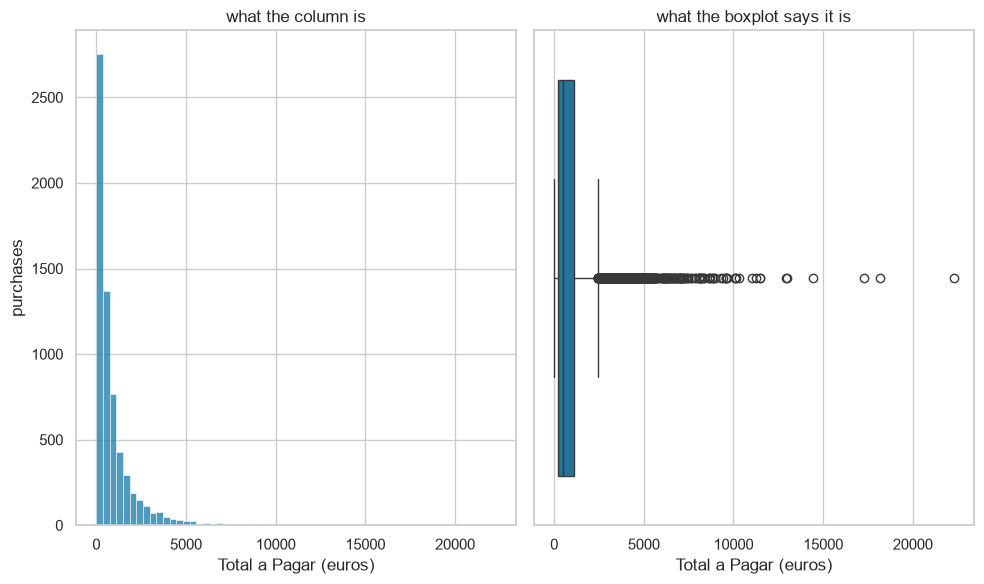

                        column      Q1       Q3  flagged  % flagged
                     spend_30d    0.00   338.24     1060      16.39
                  Total Portes    0.00     0.00     1053      16.28
             Total Desc_ Linha    0.00    92.28      822      12.71
      prior_min_purchase_value   15.45   162.61      671      11.44
           purchase_count_180d    1.00     3.00      737      11.39
                     spend_90d    0.00  1514.56      661      10.22
             prior_total_spend 1505.55 21642.32      642       9.92
                 Total a Pagar  188.92  1087.67      592       9.15
            prior_std_gap_days   32.74    78.63      461       9.12
                 Total Liquido  154.38   903.37      587       9.07
                   Total Bruto  175.74  1036.70      584       9.03
                         Custo   49.05   396.06      539       8.33
                    Total Imp_   29.93   184.84      533       8.24
           purchase_count_365d    1.00     7.00 

In [20]:
# 1.5 x IQR rule, only to see how much it would flag (nothing is removed)
fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE)
sns.histplot(checked["Total a Pagar"].dropna(), bins=60, color=PLOT_BLUE, ax=left)
left.set(xlabel="Total a Pagar (euros)", ylabel="purchases", title="what the column is")
sns.boxplot(x=checked["Total a Pagar"].dropna(), color=PLOT_BLUE, ax=right)
right.set(xlabel="Total a Pagar (euros)", title="what the boxplot says it is")
plt.tight_layout()
plt.show()

rows = []
for column in numeric:
    values = checked[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = (~values.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum()
    rows.append({"column": column, "Q1": q1, "Q3": q3, "flagged": flagged,
                 "% flagged": 100 * flagged / len(values)})
fences = pd.DataFrame(rows).sort_values("% flagged", ascending=False)
print(fences.round(2).to_string(index=False))

## 10. Which columns relate to the target

For each categorical column we compare the repeat rate across its levels and summarise
the link with Cramér's V. For the numeric columns we compare the median of each class and
use the point-biserial correlation. The strongest signals are how often the customer
bought recently (purchases in the last 365 days: r = 0.34) and how long ago they last
bought, while the value of the current purchase barely matters.

In [21]:
# rows and repeat rate per level, 10 largest levels
base_rate = raw[target].mean()
for column in categorical:
    by_level = pd.DataFrame({"rows": raw.groupby(column).size(),
                             "repeat rate": raw.groupby(column)[target].mean()})
    print(f"{column}: {len(by_level)} levels, {(by_level['rows'] < 30).sum()}"
          f" with fewer than 30 rows")
    print(by_level.nlargest(10, "rows").round(3).to_string(), "\n")

payment_type: 9 levels, 4 with fewer than 30 rows
                           rows  repeat rate
payment_type                                
Maybe Tomorrow Payment 7   4565        0.527
Maybe Tomorrow Payment 12   991        0.543
Maybe Tomorrow Payment 9    502        0.950
Maybe Tomorrow Payment 10   134        0.403
Maybe Tomorrow Payment 8     40        0.325
Maybe Tomorrow Payment 2     21        0.524
Maybe Tomorrow Payment 4      9        0.444
Maybe Tomorrow Payment 11     8        0.625
Maybe Tomorrow Payment 3      4        0.500 

salesperson: 9 levels, 3 with fewer than 30 rows
                  rows  repeat rate
salesperson                        
VLOOKUP Master 1  4054        0.624
VLOOKUP Master 4  1461        0.394
VLOOKUP Master 9   384        0.547
VLOOKUP Master 7   201        0.483
VLOOKUP Master 2   123        0.602
VLOOKUP Master 3    30        0.367
VLOOKUP Master 6    12        0.000
VLOOKUP Master 5     7        0.429
VLOOKUP Master 8     3        1.000 

commer

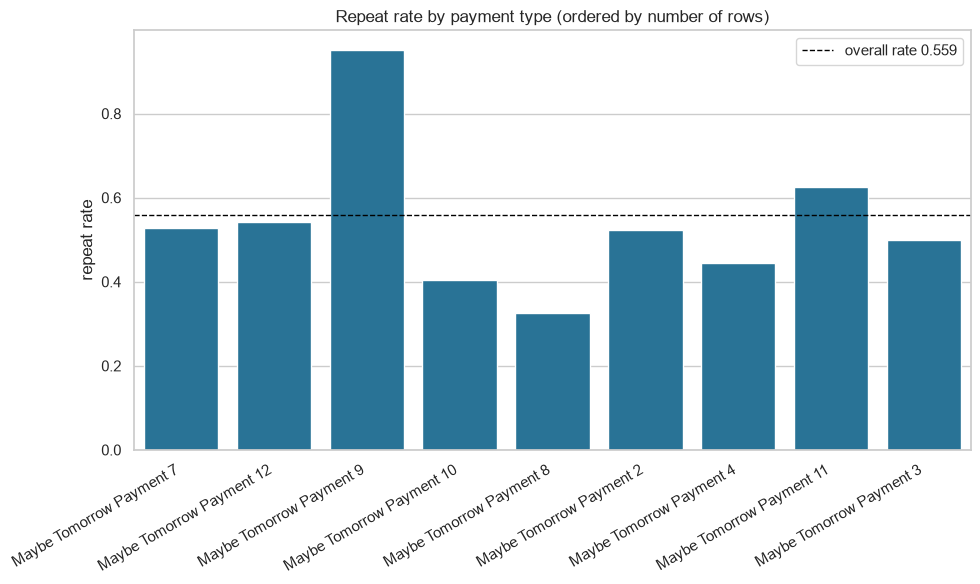

In [22]:
payment = pd.DataFrame({"rows": raw.groupby("payment_type").size(),
                        "repeat rate": raw.groupby("payment_type")[target].mean()})
payment = payment.sort_values("rows", ascending=False).reset_index()

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(payment, x="payment_type", y="repeat rate", color=PLOT_BLUE, ax=ax)
ax.axhline(base_rate, color="black", ls="--", lw=1,
           label=f"overall rate {base_rate:.3f}")
ax.set(xlabel="", ylabel="repeat rate",
       title="Repeat rate by payment type (ordered by number of rows)")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
def cramers_v(column, outcome):
    """Return the chi-square statistic, p-value, Cramér's V and smallest expected count."""
    table = pd.crosstab(column, outcome)
    if min(table.shape) < 2:
        # only one level present: nothing to measure
        return 0.0, float("nan"), 0.0, float(table.to_numpy().min())
    statistic, p, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return statistic, p, v, expected.min()


table = []
for column in categorical:
    statistic, p, v, expected = cramers_v(raw[column], raw[target])
    table.append({"column": column, "levels": raw[column].nunique(),
                  "chi2": statistic, "p": p, "Cramer's V": v,
                  "min expected": expected})
categorical_scores = pd.DataFrame(table).sort_values("Cramer's V", ascending=False)
print(categorical_scores.round(4).to_string(index=False))

          column  levels     chi2      p  Cramer's V  min expected
transport_method      80 527.2326 0.0000      0.2899        0.4400
    payment_type       9 354.3140 0.0000      0.2376        1.7616
     salesperson       9 259.4296 0.0000      0.2033        1.3243
 commercial_zone       5  26.2955 0.0000      0.0638        0.4403
       warehouse       2   5.4299 0.0198      0.0294        9.2950
 document_series       3   0.0553 0.9727      0.0029      804.7834


In [24]:
medians = checked.groupby(target)[numeric].median()

# pointbiserialr does not accept NaN, so each column uses its own filled rows
r_checked, r_raw = {}, {}
for column in numeric:
    pair = checked[[column, target]].dropna()
    r_checked[column] = pointbiserialr(pair[target], pair[column]).statistic
    pair = raw[[column, target]].dropna()
    r_raw[column] = pointbiserialr(pair[target], pair[column]).statistic

numeric_scores = pd.DataFrame({"median, target 0": medians.loc[0],
                               "median, target 1": medians.loc[1],
                               "r": r_checked,
                               "r with invalid values": r_raw})
numeric_scores["|r|"] = numeric_scores["r"].abs()
numeric_scores = numeric_scores.sort_values("|r|", ascending=False)
print(numeric_scores.round(3).to_string())

                                median, target 0  median, target 1      r  r with invalid values    |r|
purchase_count_365d                        2.000             5.000  0.340                  0.340  0.340
purchase_count_180d                        1.000             3.000  0.334                  0.334  0.334
purchase_count_90d                         0.000             1.000  0.328                  0.328  0.328
spend_180d                               457.870          2106.220  0.301                  0.301  0.301
prior_purchase_count                       6.000            17.000  0.299                  0.299  0.299
spend_90d                                  0.000           746.190  0.269                  0.269  0.269
purchase_count_30d                         0.000             0.000  0.263                  0.263  0.263
prior_total_spend                       3246.525         12098.990  0.262                  0.262  0.262
prior_mean_gap_days                      101.750            55.7

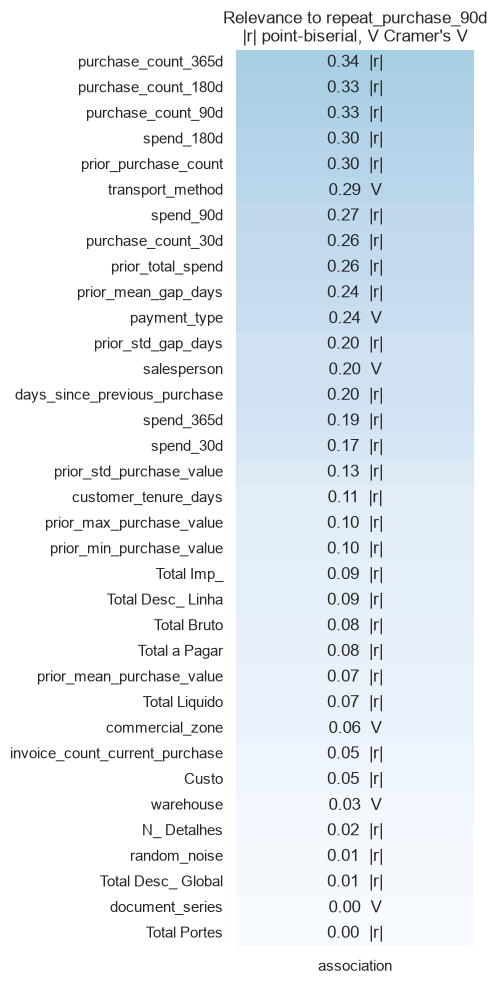

In [25]:
# both are between 0 and 1, so they can share one ranking
source_scores = pd.concat([
    numeric_scores["|r|"],
    categorical_scores.set_index("column")["Cramer's V"],
]).sort_values(ascending=False)

relevance_view = source_scores.to_frame("association")
relevance_labels = [[f"{value:.2f}  {'|r|' if name in numeric else 'V'}"]
                    for name, value in relevance_view["association"].items()]
fig, ax = plt.subplots(figsize=(5, 10))
sns.heatmap(relevance_view, annot=relevance_labels, fmt="", cmap="Blues",
            vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Relevance to repeat_purchase_90d\n|r| point-biserial, V Cramer's V",
       xlabel="", ylabel="")
fig.tight_layout()
plt.show()

## 11. Columns that repeat the same information

Of the 406 pairs of numeric columns, 23 have a correlation above 0.70. They fall into
four families: invoice totals, purchase counts over different windows, spending over
different windows, and the mean and spread of the purchase history. Columns in the same
family say almost the same thing, so feature selection should keep only one or two from each.

In [26]:
# above 0.70, a pair of columns repeats the same information
REDUNDANT = 0.70

between = checked[numeric].corr().abs()
pairs_above = [
    (numeric[i], numeric[j], between.iloc[i, j])
    for i, j in zip(*np.triu_indices_from(between, 1))
    if between.iloc[i, j] > REDUNDANT
]
print(f"pairs above {REDUNDANT}: {len(pairs_above)} of"
      f" {len(numeric) * (len(numeric) - 1) // 2}")
for left, right, value in sorted(pairs_above, key=lambda row: -row[2]):
    print(f"  {left:32s} {right:32s} {value:.3f}")

pairs above 0.7: 23 of 406
  Total a Pagar                    Total Liquido                    0.996
  Total Bruto                      Total Liquido                    0.984
  Total a Pagar                    Total Bruto                      0.975
  purchase_count_180d              purchase_count_365d              0.954
  purchase_count_90d               purchase_count_180d              0.935
  Total a Pagar                    Total Imp_                       0.901
  purchase_count_90d               purchase_count_365d              0.883
  prior_mean_purchase_value        prior_std_purchase_value         0.878
  prior_mean_gap_days              prior_std_gap_days               0.872
  Total Liquido                    Total Imp_                       0.860
  spend_90d                        spend_180d                       0.856
  purchase_count_30d               purchase_count_90d               0.845
  Total a Pagar                    Custo                            0.819
  Total Bru

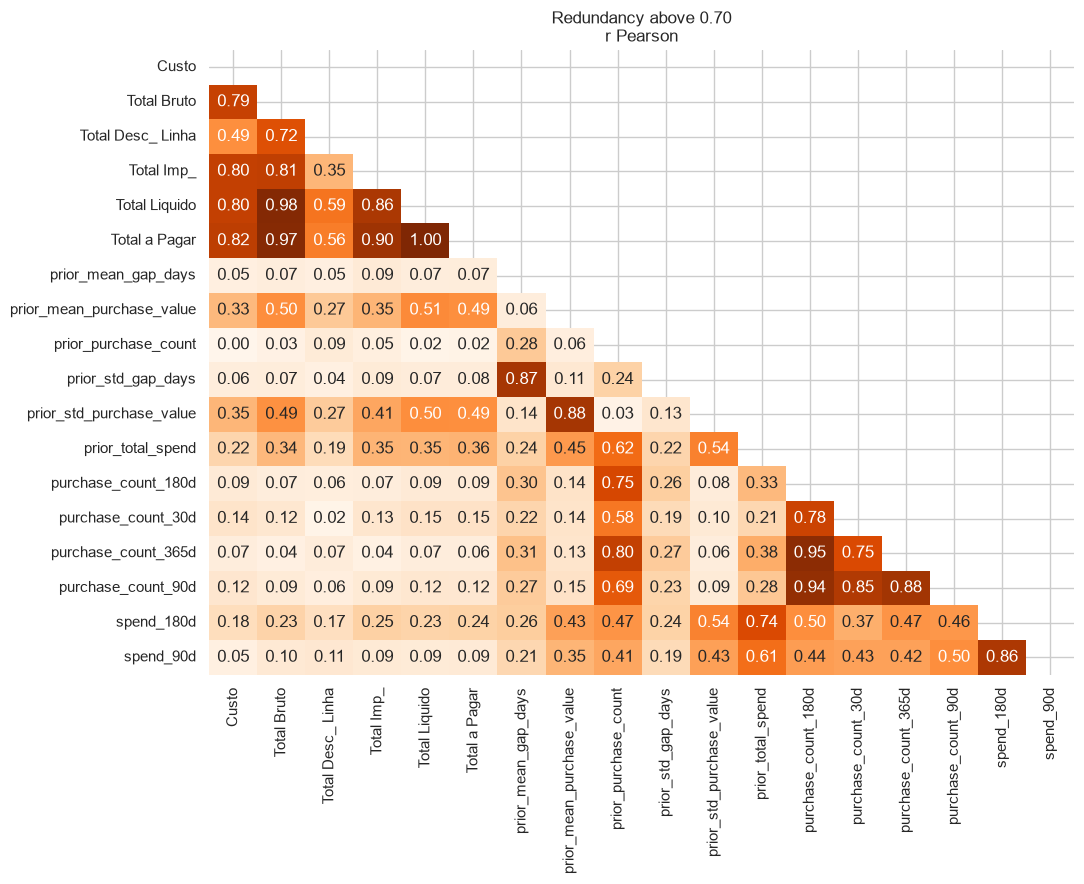

In [27]:
redundant_names = sorted({name for left, right, _ in pairs_above
                          for name in (left, right)})
redundancy_view = between.loc[redundant_names, redundant_names]
mask = np.triu(np.ones_like(redundancy_view, dtype=bool))  # hide the upper triangle
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(redundancy_view, mask=mask, annot=True, fmt=".2f",
            cmap="Oranges", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Redundancy above 0.70\nr Pearson",
       xlabel="", ylabel="")
fig.tight_layout()
plt.show()

## 12. The `random_noise` column

The project brief asks whether this column carries useful information. Its values look
like random noise (mean 0, standard deviation 1, symmetric), its correlation with the
target is −0.012, and its highest correlation with any other column is 0.029. These tests
only measure linear relationships, so we flag it as a strong candidate to drop and leave
the final decision to feature selection.

count    6469.000
mean       -0.022
std         1.001
min        -3.529
25%        -0.678
50%        -0.046
75%         0.642
max         4.151

skew: 0.054
point-biserial r with the target: -0.0120
largest |r| with another numeric column: 0.0288


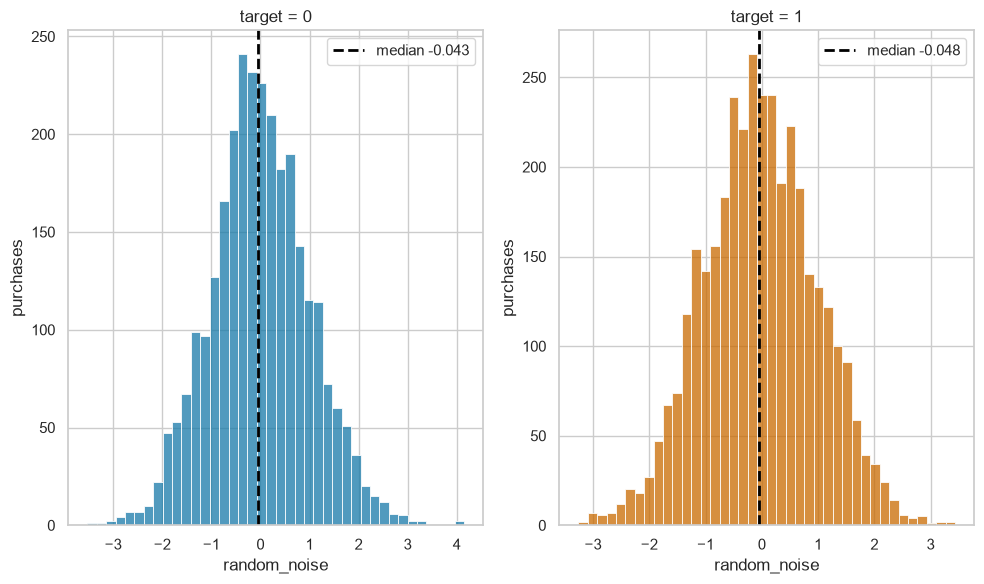

In [28]:
print(raw["random_noise"].describe().round(3).to_string())
print(f"\nskew: {raw['random_noise'].skew():.3f}")
print(f"point-biserial r with the target: {numeric_scores.loc['random_noise', 'r']:.4f}")
print(f"largest |r| with another numeric column:"
      f" {between['random_noise'].drop('random_noise').max():.4f}")

noise_0 = raw.loc[raw[target] == 0, "random_noise"].dropna()
noise_1 = raw.loc[raw[target] == 1, "random_noise"].dropna()

fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE)
sns.histplot(noise_0, bins=40, color=PLOT_BLUE, ax=left)
left.axvline(noise_0.median(), color="black", lw=2, ls="--",
             label=f"median {noise_0.median():.3f}")
left.set(xlabel="random_noise", ylabel="purchases", title="target = 0")
left.legend()
sns.histplot(noise_1, bins=40, color=PLOT_ORANGE, ax=right)
right.axvline(noise_1.median(), color="black", lw=2, ls="--",
              label=f"median {noise_1.median():.3f}")
right.set(xlabel="random_noise", ylabel="purchases", title="target = 1")
right.legend()
plt.tight_layout()
plt.show()

## 13. Dates

The training data runs from 2015-07-11 to 2025-02-15, and the test set covers
2025-05-24 to 2026-10-06, so every test purchase is later than every training purchase.
The model has to predict future purchases from past ones, so our validation also has to
train on earlier purchases and check on later ones. The date itself is not used as a
feature; the time information is already in columns such as days since the previous
purchase and the purchase counts over 30 to 365 days.

In [29]:
# dates are YYYY-MM-DD strings, so min/max still work
print("first purchase:", raw["purchase_date"].dropna().min())
print("last purchase: ", raw["purchase_date"].dropna().max())
print("distinct dates:", raw["purchase_date"].nunique(),
      "| nulls:", raw["purchase_date"].isna().sum())

first purchase: 2015-07-11
last purchase:  2025-02-15
distinct dates: 1492 | nulls: 65


## 14. The optional `clientes.csv` table

Every customer in the training data appears in this table, so it can be joined through
`customer_id`. Most of its columns, however, are empty, identify the customer (company
name, address), or have hundreds of levels for only 610 customers. Only three look
usable: `customer_since_year`, `country_or_region` and `commercial_region`. Whether
to add them is decided and tested in the preprocessing notebook.

In [30]:
clientes = pd.read_csv("../data/clientes.csv", index_col="customer_id")
print(f"{clientes.shape[0]:,} rows x {clientes.shape[1]} columns,"
      f" {clientes.index.nunique():,} distinct customer_id")

print(f"training rows whose customer is in clientes.csv:"
      f" {100 * raw['customer_id'].isin(clientes.index).mean():.2f}%")
in_train = clientes[clientes.index.isin(raw["customer_id"])]
print(f"customers in clientes.csv that appear in the training data:"
      f" {len(in_train)} of {len(clientes)}\n")

in_train.info()
pd.DataFrame({"% nulls": (100 * in_train.isna().mean()).round(1),
              "levels": in_train.nunique()})

1,143 rows x 12 columns, 1,143 distinct customer_id
training rows whose customer is in clientes.csv: 100.00%
customers in clientes.csv that appear in the training data: 610 of 1143

<class 'pandas.DataFrame'>
Index: 610 entries, 770941 to 994493
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country_or_region    610 non-null    str    
 1   commercial_region    598 non-null    str    
 2   island               324 non-null    str    
 3   municipality         569 non-null    str    
 4   city                 374 non-null    str    
 5   postal_area          570 non-null    str    
 6   postal_code          590 non-null    str    
 7   street               280 non-null    str    
 8   address              610 non-null    str    
 9   customer_type        0 non-null      float64
 10  company_name         610 non-null    str    
 11  customer_since_year  610 non-null    int64  
dtypes: float64(1), i

,% nulls,levels
country_or_region,0.0,7
commercial_region,2.0,32
island,46.9,10
municipality,6.7,150
city,38.7,260
postal_area,6.6,189
postal_code,3.3,519
street,54.1,266
address,0.0,600
customer_type,100.0,0


## Summary

- Impossible values (−4 days, €1,000,000,000, means above the maximum) and structural
  missing values have to be handled in preprocessing.
- 27 of the 29 numeric columns have long right tails: the median describes them better
  than the mean, and they are candidates for a log transform. Large values are real
  purchases, so no rows are removed as outliers.
- How often a customer bought recently, and how long ago, are the strongest signals;
  the value of the current purchase barely matters.
- 23 pairs of numeric columns repeat the same information, and `random_noise` shows no
  sign of useful information.
- The test set comes later in time, so evaluation has to train on the past and validate
  on the future.